# LA Parking Citations — District Visualization

This notebook provides exploratory geospatial analysis and visualization of the Gold-layer parking citation data produced by the LA Parking Citations pipeline.

The data pipeline is organized into three processing notebooks:

1. **01_ingest_bronze** — Ingest parking citation data from the LA Open Data API.
2. **02_transform_silver** — Clean, standardize, validate, and quarantine citation records.
3. **03_enrich_gold** — Enrich valid citations with Los Angeles City Council district boundaries.

This fourth notebook consumes the completed Gold dataset for analysis and visualization. It is not a required task in the Lakeflow pipeline.

## Notebook 4: District Visualization

This notebook uses `parking_citations_gold` to explore the geographic distribution of parking citations across Los Angeles City Council districts.

Analysis includes:

- Summarizing citation counts by council district
- Mapping citation locations across all council districts
- Visualizing citations within an individual selected district
- Exploring geographic patterns in the enriched Gold data

**Input:** `parking_citations_gold`  
**Purpose:** Exploratory analysis and visualization

In [0]:
%pip install geopandas

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
%restart_python

In [0]:
import geopandas as gpd

## 1. Load Gold Data

Load the completed Gold Delta table containing validated parking citations enriched with Los Angeles City Council district information.

In [0]:
gold_df = spark.table("parking_citations_gold")

print(f"Gold records loaded: {gold_df.count():,}")
display(gold_df.limit(10))

Gold records loaded: 49,954


ticket_number,issue_date,issue_time,meter_id,marked_time,rp_state_plate,plate_expiry_date,vin,make,body_style,color,location,route,agency,violation_code,violation_description,fine_amount,agency_desc,color_desc,body_style_desc,loc_lat,loc_long,geocodelocation,issue_time_formatted,valid_coordinates,valid_ticket_number,valid_issue_date,valid_issue_time,valid_fine_amount,valid_violation_code,quarantine_reason,District,District_Name
4604674491,2025-06-05T00:00:00.000Z,819,null,0000,CA,202412,null,KIA,PA,BK,6658 WOODMAN AVE,null,53,4000(a)1,EXPIRED REGISTRATION,50.0,53 - DOT - VALLEY,BLACK,PASSENGER CAR,34.19198497,-118.43122744,"{'type': 'Point', 'coordinates': [-118.43122744, 34.19198497]}",08:19,true,true,true,true,true,true,null,2,2 - Adrin Nazarian
4604684641,2025-06-05T00:00:00.000Z,856,null,0000,CA,202512,null,LEXS,PA,RD,625 LANDFAIR AVE,null,51,80.69BS,NO PARK/STREET CLEAN,73.0,51 - DOT - WESTERN,RED,PASSENGER CAR,34.06642216,-118.44903759,"{'type': 'Point', 'coordinates': [-118.44903759, 34.06642216]}",08:56,true,true,true,true,true,true,null,5,5 - Katy Yaroslavsky
4603959006,2025-06-05T00:00:00.000Z,902,null,0000,CA,202409,null,DODG,VN,BK,20700 BRYANT ST,null,53,80.69BS,NO PARK/STREET CLEAN,73.0,53 - DOT - VALLEY,BLACK,VAN,34.2269981,-118.5861034,"{'type': 'Point', 'coordinates': [-118.5861034, 34.2269981]}",09:02,true,true,true,true,true,true,null,3,3 - Bob Blumenfield
4604675740,2025-06-05T00:00:00.000Z,837,null,0000,CA,202601,null,AUDI,PA,GY,3118 LA SALLE AVE S,null,55,80.69BS,NO PARK/STREET CLEAN,73.0,55 - DOT - SOUTHERN,GREY,PASSENGER CAR,34.02576288,-118.30555308,"{'type': 'Point', 'coordinates': [-118.30555308, 34.02576288]}",08:37,true,true,true,true,true,true,null,8,8 - Marqueece Harris-Dawson
4604443071,2025-06-05T00:00:00.000Z,845,null,0000,CA,202512,null,HYUN,PA,WT,3795 ROSEWOOD AV,null,51,80.69BS,NO PARK/STREET CLEAN,73.0,51 - DOT - WESTERN,WHITE,PASSENGER CAR,33.99900646,-118.44362349,"{'type': 'Point', 'coordinates': [-118.44362349, 33.99900646]}",08:45,true,true,true,true,true,true,null,11,11 - Traci Park
4604637715,2025-06-05T00:00:00.000Z,1233,null,0000,CA,202501,null,HYUN,PA,BK,1330 35TH PL W,null,55,80.69BS,NO PARK/STREET CLEAN,73.0,55 - DOT - SOUTHERN,BLACK,PASSENGER CAR,34.02371719,-118.29833515,"{'type': 'Point', 'coordinates': [-118.29833515, 34.02371719]}",12:33,true,true,true,true,true,true,null,8,8 - Marqueece Harris-Dawson
4604657960,2025-06-05T00:00:00.000Z,1040,null,0000,AZ,202509,null,TOYT,PA,BK,5216 ROSELAND ST,null,55,80.58L,PREFERENTIAL PARKING,68.0,55 - DOT - SOUTHERN,BLACK,PASSENGER CAR,34.02841185,-118.35784251,"{'type': 'Point', 'coordinates': [-118.35784251, 34.02841185]}",10:40,true,true,true,true,true,true,null,10,10 - Heather Hutt
4604096151,2025-06-05T00:00:00.000Z,856,HO667,0000,CA,202506,null,TOYT,PA,BL,1701 CHEROKEE AV,null,54,88.13B+,METER EXP.,63.0,54 - DOT - HOLLYWOOD,BLUE,PASSENGER CAR,34.1019943,-118.3347587,"{'type': 'Point', 'coordinates': [-118.3347587, 34.1019943]}",08:56,true,true,true,true,true,true,null,13,13 - Hugo Soto-Martinez
4604217914,2025-06-03T00:00:00.000Z,1016,null,0000,CA,202510,null,TOYT,PA,WT,3120 71ST ST W,null,55,80.69BS,NO PARK/STREET CLEAN,73.0,55 - DOT - SOUTHERN,WHITE,PASSENGER CAR,33.9754104,-118.3273543,"{'type': 'Point', 'coordinates': [-118.3273543, 33.9754104]}",10:16,true,true,true,true,true,true,null,8,8 - Marqueece Harris-Dawson
4604735450,2025-06-05T00:00:00.000Z,1225,null,0000,CA,202405,null,HOND,PA,GY,1144 39TH ST W,null,55,80.69BS,NO PARK/STREET CLEAN,73.0,55 - DOT - SOUTHERN,GREY,PASSENGER CAR,34.0155554,-118.2956359,"{'type': 'Point', 'coordinates': [-118.2956359, 34.0155554]}",12:25,true,true,true,true,true,true,null,8,8 - Marqueece Harris-Dawson


## 2. Citation Summary by Council District

Summarize the number of parking citations assigned to each Los Angeles City Council district.

In [0]:
from pyspark.sql import functions as F

district_summary = (
    gold_df
    .groupBy("District", "District_Name")
    .agg(
        F.count("*").alias("citation_count")
    )
    .orderBy("District")
)

display(district_summary)

District,District_Name,citation_count
null,null,179
1,1 - Eunisses Hernandez,4144
2,2 - Adrin Nazarian,1939
3,3 - Bob Blumenfield,1053
4,4 - Nithya Raman,4399
5,5 - Katy Yaroslavsky,5656
6,6 - Imelda Padilla,2010
7,7 - Monica Rodriguez,675
8,8 - Marqueece Harris-Dawson,3082
9,9 - Curren D. Price Jr.,3014


## 3. Map Council Districts and Citation Locations

Visualize Los Angeles City Council district boundaries together with the parking citation locations contained in the Gold dataset.

In [0]:
import requests
import json
from io import StringIO

city_council_url = (
    "https://maps.lacity.org/lahub/rest/services/"
    "Boundaries/MapServer/13/query"
    "?where=1%3D1"
    "&outFields=*"
    "&outSR=4326"
    "&f=json"
)

response = requests.get(city_council_url)
response.raise_for_status()

districts_gdf = gpd.read_file(
    StringIO(json.dumps(response.json()))
)

In [0]:
gold_pdf = gold_df.toPandas()

citations_gdf = gpd.GeoDataFrame(
    gold_pdf,
    geometry=gpd.points_from_xy(
        gold_pdf["loc_long"],
        gold_pdf["loc_lat"]
    ),
    crs="EPSG:4326"
)

In [0]:
print("District CRS:", districts_gdf.crs)
print("Citation CRS:", citations_gdf.crs)
print(f"Citation points: {len(citations_gdf):,}")

District CRS: EPSG:4326
Citation CRS: EPSG:4326
Citation points: 49,954


### All Council Districts and Citation Locations

Plot all Los Angeles City Council district boundaries and overlay the Gold-layer parking citation locations to visualize their geographic distribution across the city.

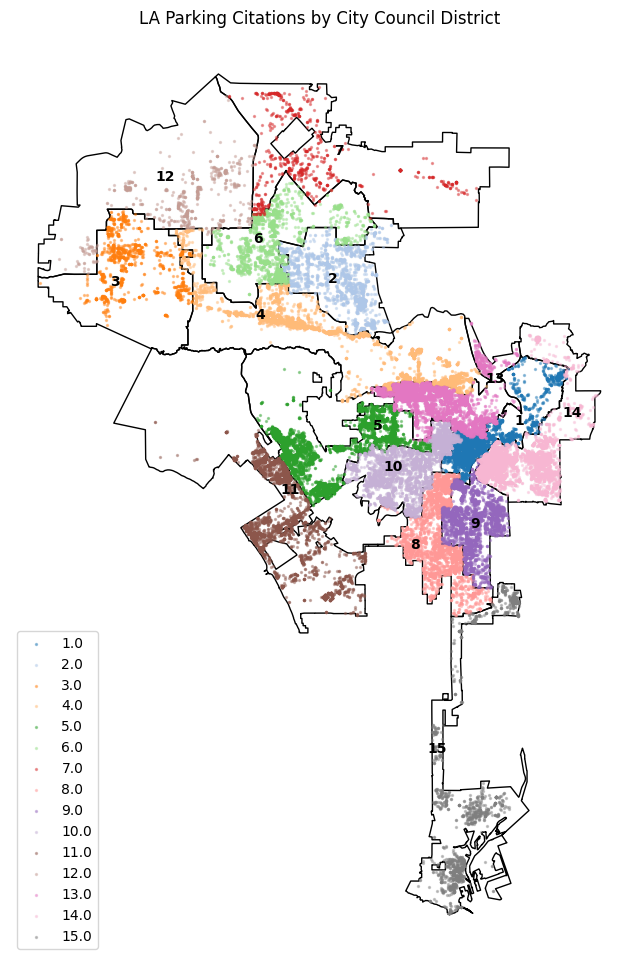

In [0]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

# Plot council district boundaries
districts_gdf.plot(
    ax=ax,
    edgecolor="black",
    facecolor="none",
    linewidth=1
)

# Plot citation points with a different color for each district
citations_gdf.plot(
    ax=ax,
    column="District",
    categorical=True,
    cmap="tab20",
    markersize=2,
    alpha=0.4,
    legend=True
)

ax.set_title("LA Parking Citations by City Council District")
# Add district number labels
for _, district in districts_gdf.iterrows():
    label_point = district.geometry.representative_point()

    ax.text(
        label_point.x,
        label_point.y,
        str(district["District"]),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )
ax.set_axis_off()

plt.show()